# Linear BVP

## Problem
$$
y'' = -\pi^2 \sin(\pi x), \quad 0<x<1, \quad y(0)=y(1)=0
$$
Exact solution $y = \sin(\pi x)$.

## Discretization
Central differences on $x_i = ih$ give

$$
\frac{y_{i-1} - 2y_i + y_{i+1}}{h^2} = f(x_i)
$$

which is a tridiagonal system for the interior nodes, solved with `solve_banded`.

## Code

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from fd_ode import linear_bvp

In [2]:
# Exact: sin(pi x)
f = lambda x: -np.pi**2*np.sin(np.pi*x)

In [3]:
results = []
for N in [10, 20, 40, 80]:
    x, y = linear_bvp(f, 0, 1, 0, 0, N)
    e = np.linalg.norm(y-np.sin(np.pi*x), np.inf)
    results.append({'h': 1/N, 'err': e})
df = pd.DataFrame(results)
df['order'] = np.log2(df['err'].shift()/df['err'])
df

,h,err,order
0,0.1000,0.008265,NaN
1,0.0500,0.002059,2.005349
2,0.0250,0.000514,2.001335
3,0.0125,0.000129,2.000334


### Convergence

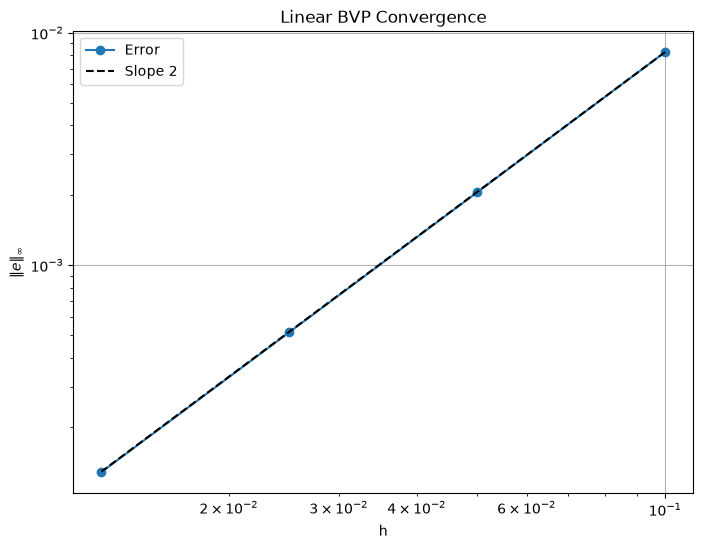

In [4]:
h = df['h'].values
plt.figure(figsize=(8, 6))
plt.loglog(h, df['err'], 'o-', label="Error")
plt.loglog(h, df['err'][0]*(h/h[0])**2, 'k--', label=r"Slope 2")
plt.xlabel("h")
plt.ylabel(r"$\|e\|_\infty$")
plt.title("Linear BVP Convergence")
plt.legend()
plt.grid(True)
plt.savefig("../figures/01_convergence.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusion
Halving h cuts the error by a factor of 4, so the scheme is second order. The data sits on the slope 2 line at all four grids.